In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

In [2]:


def _resolve_overlaps(df: pd.DataFrame) -> pd.DataFrame:
    """Sort by start; merge same-behavior overlaps, clip different-behavior overlaps."""
    df = df.sort_values("start").reset_index(drop=True)
    result = []
    i = 0
    while i < len(df):
        cur = df.iloc[i].copy()
        while i + 1 < len(df):
            nxt = df.iloc[i + 1]
            if nxt["start"] >= cur["end"]:
                break                                      # no overlap
            if nxt["Behavior"] == cur["Behavior"]:
                cur["end"] = max(cur["end"], nxt["end"])  # merge
                i += 1
            else:
                cur["end"] = nxt["start"]                 # clip
                break
        if cur["end"] > cur["start"]:                     # drop zero-length
            result.append(cur)
        i += 1
    return pd.DataFrame(result).reset_index(drop=True)


In [3]:

# ── Intervals for this animal/session ─────────────────────────────────────────
behavior_df = pd.read_csv('/Users/amonast/Desktop/miniscope/data/intervals_allmice.csv', index_col=0)
behavior_df["time"] = pd.to_timedelta(behavior_df["time"])


records = []
for (animal, session, behavior, btype), grp in behavior_df.groupby(
    ["animal", "session", "Behavior", "behavior_type"]
):
    starts = grp[grp["Event_Type"] == "State start"]["time"].dt.total_seconds().to_numpy()
    stops  = grp[grp["Event_Type"] == "State stop" ]["time"].dt.total_seconds().to_numpy()
    for s, e in zip(starts, stops):
        records.append(dict(animal=animal, session=session,
                            Behavior=behavior, behavior_type=btype,
                            start=s, end=e))

intervals = (
    pd.DataFrame(records)
    .groupby(["animal", "session"], group_keys=False)
    .apply(_resolve_overlaps)
    .reset_index(drop=True)
)


In [4]:
intervals

,animal,session,Behavior,behavior_type,start,end
0,C1F2,R1,Escape,Social Avoidance,128.523,129.324
1,C1F2,R1,Tail Sniffing,Pro-Social,131.191,132.091
2,C1F2,R1,Tail Sniffing,Pro-Social,132.892,133.826
3,C1F2,R1,Face Sniffing,Pro-Social,137.160,139.795
4,C1F2,R1,Body Sniffing,Pro-Social,139.928,141.362
...,...,...,...,...,...,...
4110,C3M4,R2,Body Sniffing,Pro-Social,715.281,715.615
4111,C3M4,R2,Face Sniffing,Pro-Social,715.681,717.015
4112,C3M4,R2,Face Sniffing,Pro-Social,717.349,718.183
4113,C3M4,R2,Digging,Social Avoidance,719.783,720.350


In [5]:
intervals["duration"] = intervals["end"] - intervals["start"]

# ── Total time = sum of all interval durations, per animal/session ────────────
total_time = (
    intervals
    .groupby(["animal", "session"])["duration"]
    .sum()
    .rename("total_duration")
)

# ── Sum duration per animal / session / behavior_type ─────────────────────────
duration_summary = (
    intervals
    .groupby(["animal", "session", "behavior_type"])["duration"]
    .sum()
    .reset_index()
)

duration_summary = duration_summary.join(total_time, on=["animal", "session"])
duration_summary["proportion"] = duration_summary["duration"] / duration_summary["total_duration"]


In [6]:
duration_summary['sex']=duration_summary['animal'].str[2]

In [7]:
duration_summary

,animal,session,behavior_type,duration,total_duration,proportion,sex
0,C1F2,R1,Aggressive,62.361,312.996,0.199239,F
1,C1F2,R1,Other,21.943,312.996,0.070106,F
2,C1F2,R1,Pro-Social,125.014,312.996,0.399411,F
3,C1F2,R1,Social Avoidance,103.678,312.996,0.331244,F
4,C1F2,R2,Aggressive,169.840,310.675,0.546681,F
...,...,...,...,...,...,...,...
71,C3M4,R1,Social Avoidance,91.508,276.389,0.331084,M
72,C3M4,R2,Aggressive,11.072,201.257,0.055014,M
73,C3M4,R2,Other,11.206,201.257,0.055680,M
74,C3M4,R2,Pro-Social,144.965,201.257,0.720298,M


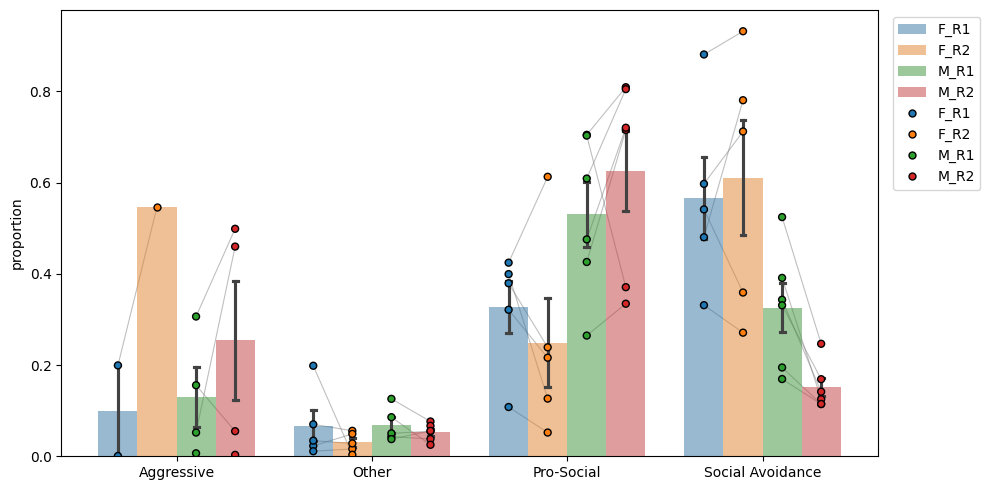

In [8]:
duration_summary["sex_session"] = duration_summary["sex"] + "_" + duration_summary["session"]

hue_order = ["F_R1", "F_R2", "M_R1", "M_R2"]
# with 4 hues seaborn places groups at -0.3, -0.1, +0.1, +0.3
hue_xoff = {h: -0.3 + i * 0.2 for i, h in enumerate(hue_order)}

fig, ax = plt.subplots(figsize=(10, 5))

sb.barplot(data=duration_summary, x='behavior_type', y='proportion', hue='sex_session',
           hue_order=hue_order, alpha=0.5, ax=ax, errorbar='se', capsize=.1)
sb.stripplot(data=duration_summary, x='behavior_type', y='proportion', hue='sex_session',
             hue_order=hue_order, dodge=True, jitter=0, ax=ax, edgecolor='k', linewidth=1)

btype_order = [t.get_text() for t in ax.get_xticklabels()]
btype_to_x  = {bt: i for i, bt in enumerate(btype_order)}

for animal, animal_grp in duration_summary.groupby("animal"):
    sex = animal_grp["sex"].iloc[0]
    for bt, bt_grp in animal_grp.groupby("behavior_type"):
        r1 = bt_grp[bt_grp["session"] == "R1"]["proportion"].values
        r2 = bt_grp[bt_grp["session"] == "R2"]["proportion"].values
        if len(r1) and len(r2):
            x = btype_to_x[bt]
            ax.plot(
                [x + hue_xoff[f"{sex}_R1"], x + hue_xoff[f"{sex}_R2"]],
                [r1[0], r2[0]],
                color="gray", alpha=0.5, linewidth=0.8, zorder=0
            )

ax.set_xlabel("")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [13]:
import matplotlib
import pingouin as pg
matplotlib.style.use('paper_style.mplstyle')

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.6.1.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


In [14]:
duration_summary

,animal,session,behavior_type,duration,total_duration,proportion,sex,sex_session
0,C1F2,R1,Aggressive,62.361,312.996,0.199239,F,F_R1
1,C1F2,R1,Other,21.943,312.996,0.070106,F,F_R1
2,C1F2,R1,Pro-Social,125.014,312.996,0.399411,F,F_R1
3,C1F2,R1,Social Avoidance,103.678,312.996,0.331244,F,F_R1
4,C1F2,R2,Aggressive,169.840,310.675,0.546681,F,F_R2
...,...,...,...,...,...,...,...,...
71,C3M4,R1,Social Avoidance,91.508,276.389,0.331084,M,M_R1
72,C3M4,R2,Aggressive,11.072,201.257,0.055014,M,M_R2
73,C3M4,R2,Other,11.206,201.257,0.055680,M,M_R2
74,C3M4,R2,Pro-Social,144.965,201.257,0.720298,M,M_R2


Social Avoidance
        Source        SS  DF1  DF2        MS          F     p-unc       np2  \
0          sex  0.667344    1    9  0.667344  12.137355  0.006896  0.574214   
1      session  0.030459    1    9  0.030459   3.115620  0.111362  0.257157   
2  Interaction  0.065079    1    9  0.065079   6.656918  0.029692  0.425174   

   eps  
0  NaN  
1  1.0  
2  NaN  
        Contrast sex   A   B Paired  Parametric         T        dof  \
0            sex   -   F   M  False        True  3.229672   4.983152   
1        session   -  R1  R2   True        True  1.410649  10.000000   
2  sex * session   F  R1  R2   True        True -0.549095   4.000000   
3  sex * session   M  R1  R2   True        True  4.578982   5.000000   

  alternative     p-unc    p-corr p-adjust    BF10    hedges  
0   two-sided  0.023327       NaN      NaN   5.096  1.928767  
1   two-sided  0.188690       NaN      NaN   0.654  0.279172  
2   two-sided  0.612152  0.612152   fdr_bh   0.449 -0.164261  
3   two-sided  0.

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:478: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  tmp = data.groupby([subject, f], as_index=False, observed=True, sort=True).mean()
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:583: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  stats.loc[:, "Parametric"] = parametric
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:478: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprec

Aggressive
        Source        SS  DF1  DF2        MS         F     p-unc       np2  \
0          sex  0.021004    1    2  0.021004  0.475575  0.561700  0.192107   
1      session  0.089613    1    2  0.089613  2.751498  0.239027  0.579080   
2  Interaction  0.012288    1    2  0.012288  0.377303  0.601615  0.158710   

   eps  
0  NaN  
1  1.0  
2  NaN  
        Contrast sex   A   B Paired  Parametric         T  dof alternative  \
0            sex   -   F   M  False        True       NaN  1.0   two-sided   
1        session   -  R1  R2   True        True -1.863387  3.0   two-sided   
2  sex * session   F  R1  R2   True        True       NaN  0.0   two-sided   
3  sex * session   M  R1  R2   True        True -1.129407  2.0   two-sided   

      p-unc    p-corr p-adjust   BF10    hedges  
0       NaN       NaN      NaN    nan       NaN  
1  0.159294       NaN      NaN  1.086 -1.043292  
2       NaN       NaN   fdr_bh    nan       NaN  
3  0.375967  0.375967   fdr_bh   0.71 -0.679699  

/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/pairwise.py:478: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  tmp = data.groupby([subject, f], as_index=False, observed=True, sort=True).mean()
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/pingouin/parametric.py:257: RuntimeWarning: Degrees of freedom <= 0 for slice
  vx, vy = x.var(ddof=1), y.var(ddof=1)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/Users/amonast/opt/anaconda3/envs/caiman/lib/python3.10/site-packages/scipy/stats/_stats_py.py:1087: RuntimeWarning: divide by zero encountered in divide
  var *= np.divide(n, n-ddof)  # to avoid error

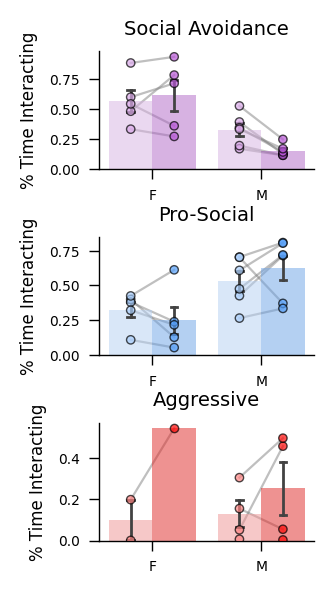

In [19]:
BTYPES = ["Social Avoidance", "Pro-Social", "Aggressive"]
DODGE  = 0.2
session_xoff = {"R1": -DODGE, "R2": DODGE}
sex_order = ["F", "M"]
sex_to_x  = {s: i for i, s in enumerate(sex_order)}
agg_palette   = ["#fe8382","#fe0806",]
social_palette   = ["#aacffd","#55a0fb"]
avoidance_palette    = ["#dbaaea","#b856d7"]
palettes = [avoidance_palette,social_palette,agg_palette]
height=2.8
width=1.5
fig, axes = plt.subplots(nrows=3, ncols=1, dpi=200, figsize=(width, height), sharey=False)

for i,(ax, btype) in enumerate(zip(axes, BTYPES)):
    sub = duration_summary[duration_summary["behavior_type"] == btype]

    sb.barplot(data=sub, x='sex', y='proportion', hue='session',palette=palettes[i],
               err_kws={'linewidth':1,},
               order=sex_order, alpha=0.5, ax=ax, errorbar='se', capsize=.12,legend=False)
    sb.stripplot(data=sub, x='sex', y='proportion', hue='session',palette=palettes[i],
                 order=sex_order, dodge=True, jitter=0, ax=ax,legend=False,
                 edgecolor='k', size=3,alpha=.7,linewidth=.5)
    print(btype)
    print(pg.mixed_anova(data=sub,dv='proportion',
                         between='sex',within='session',subject='animal'))
    print(pg.pairwise_tests(data=sub,dv='proportion',padjust='fdr_bh',within_first=False,
                         between='sex',within='session',subject='animal'))
    for animal, animal_grp in sub.groupby("animal"):
        sex = animal_grp["sex"].iloc[0]
        r1 = animal_grp[animal_grp["session"] == "R1"]["proportion"].values
        r2 = animal_grp[animal_grp["session"] == "R2"]["proportion"].values
        if len(r1) and len(r2):
            x = sex_to_x[sex]
            ax.plot(
                [x + session_xoff["R1"], x + session_xoff["R2"]],
                [r1[0], r2[0]],
                color="gray", alpha=0.5, linewidth=0.8, zorder=0
            )
    ax.set_ylabel('% Time Interacting',size=6)
    ax.set_title(btype,size=7)
    ax.set_xlabel("")
    ax.tick_params(axis='both', labelsize=5,width=.5)
    sb.despine()
    for sp in ax.spines.values():
        sp.set_linewidth(.5)

plt.tight_layout(pad=0.1,h_pad=0.1)
plt.savefig('figures/behavior_barplots.svg',transparent=True)

In [26]:
intervals

,animal,session,Behavior,behavior_type,start,end,duration
0,C1F2,R1,Escape,Social Avoidance,128.523,129.324,0.801
1,C1F2,R1,Tail Sniffing,Pro-Social,131.191,132.091,0.900
2,C1F2,R1,Tail Sniffing,Pro-Social,132.892,133.826,0.934
3,C1F2,R1,Face Sniffing,Pro-Social,137.160,139.795,2.635
4,C1F2,R1,Body Sniffing,Pro-Social,139.928,141.362,1.434
...,...,...,...,...,...,...,...
4110,C3M4,R2,Body Sniffing,Pro-Social,715.281,715.615,0.334
4111,C3M4,R2,Face Sniffing,Pro-Social,715.681,717.015,1.334
4112,C3M4,R2,Face Sniffing,Pro-Social,717.349,718.183,0.834
4113,C3M4,R2,Digging,Social Avoidance,719.783,720.350,0.567


In [28]:
# ── 4-category color map ──────────────────────────────────────────────────────
color_map_categories = {
    'Aggressive':        "#C54A4A",
    'Pro-Social':        "#57A35B",
    'Social Avoidance':  '#7B1FA2',
    'Other':             '#78909C',
    
}

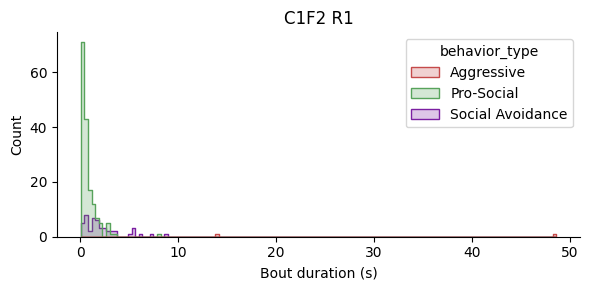

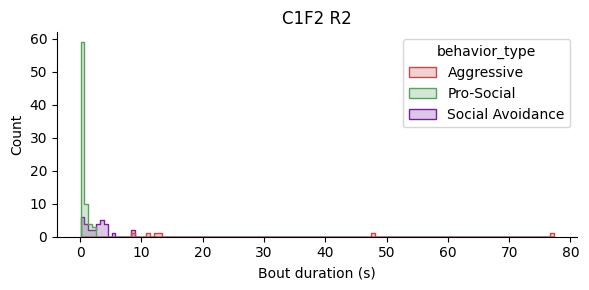

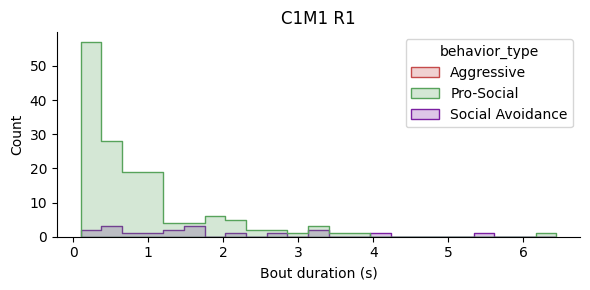

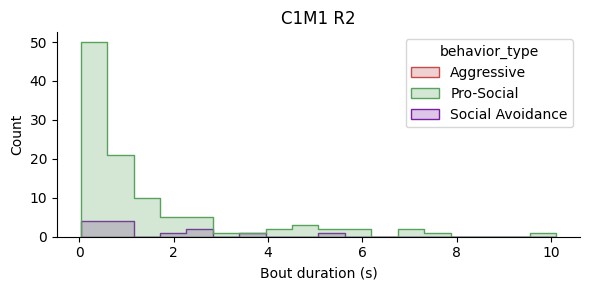

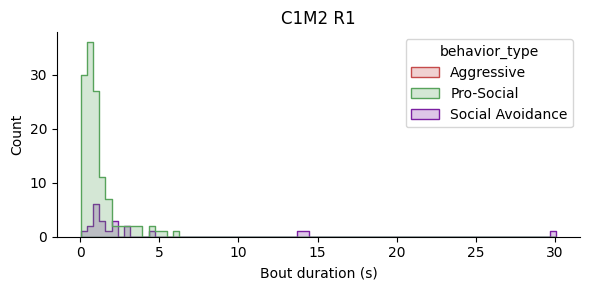

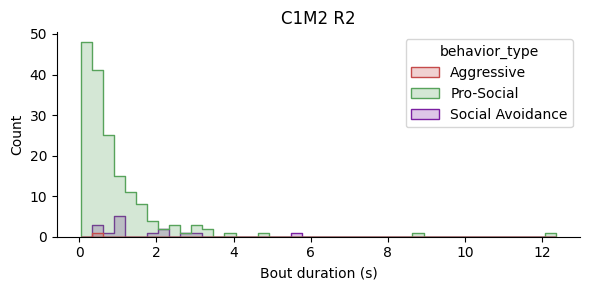

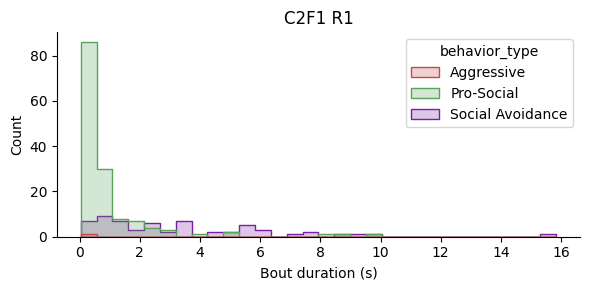

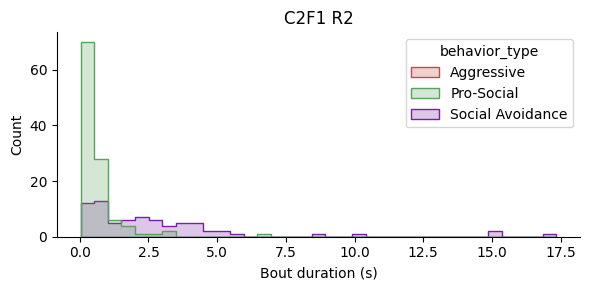

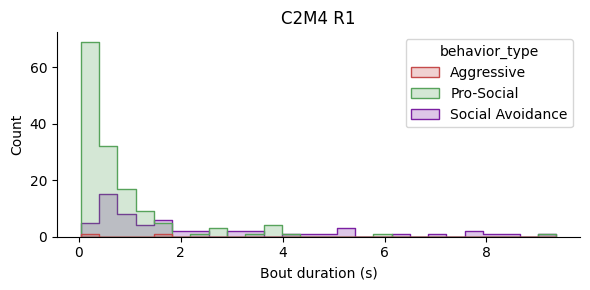

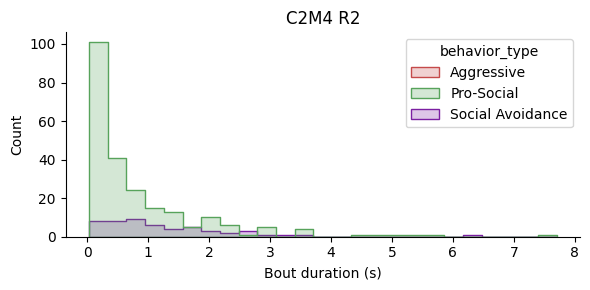

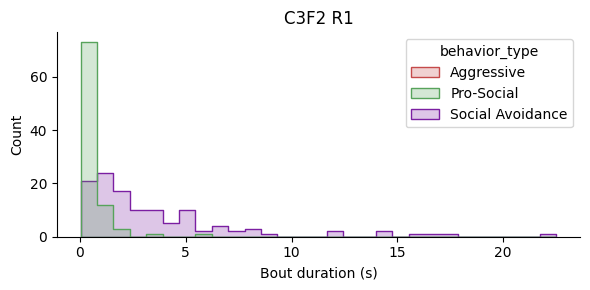

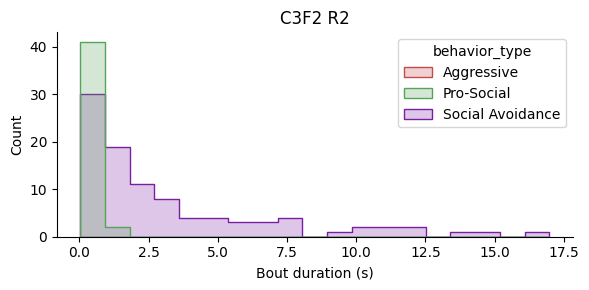

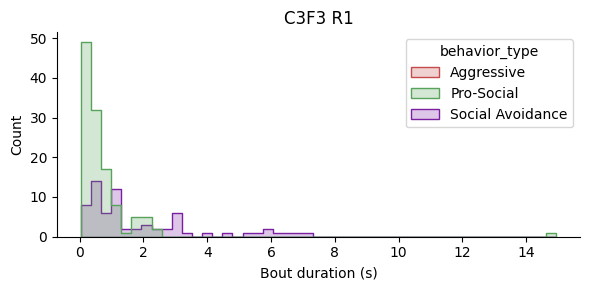

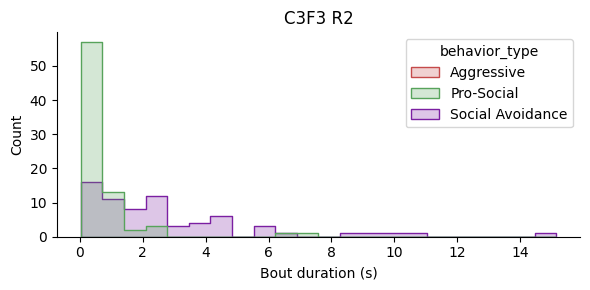

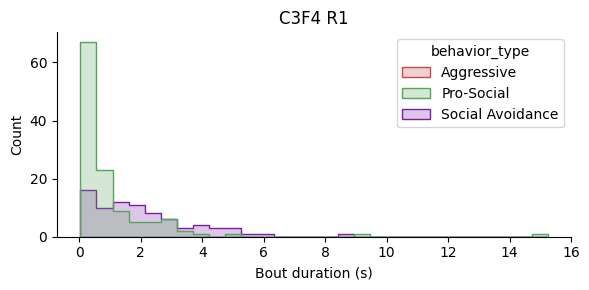

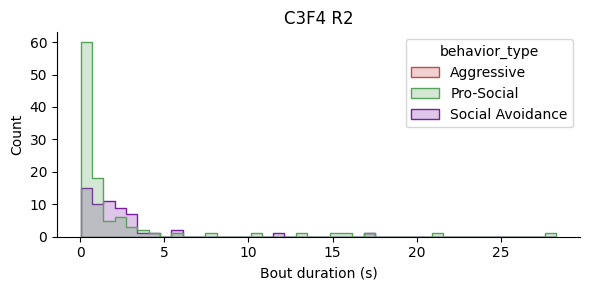

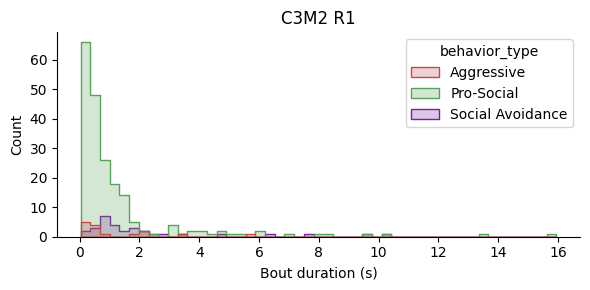

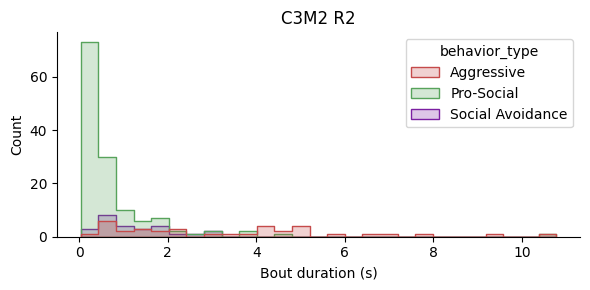

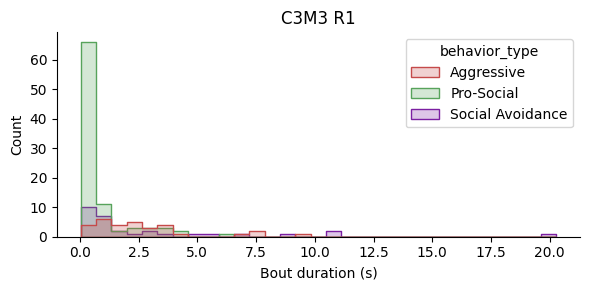

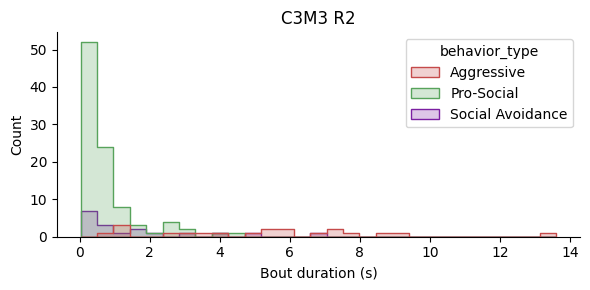

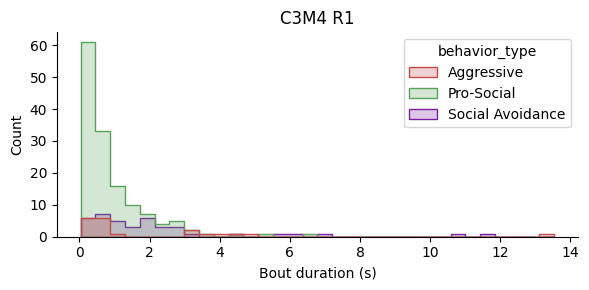

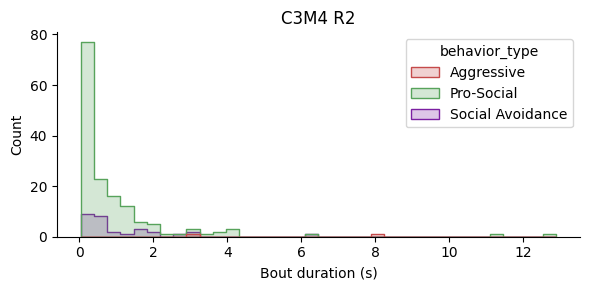

In [29]:
CATEGORIES = ["Aggressive", "Pro-Social", "Social Avoidance"]

plot_df = intervals[intervals["behavior_type"].isin(CATEGORIES)]

for (animal, session), grp in plot_df.groupby(["animal", "session"]):
    fig, ax = plt.subplots(figsize=(6, 3))

    sb.histplot(
        data=grp,
        x="duration",
        hue="behavior_type",
        hue_order=CATEGORIES,
        palette=color_map_categories,
        element="step",
        stat="count",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"{animal} {session}")
    ax.set_xlabel("Bout duration (s)")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()
